# load and prepare original dataset

In [ ]:
#@title download and unzip data
import urllib.request

dataset_url = "https://zenodo.org/records/8252482/files/Soundwel%20Dataset%20-%20Audio%20and%20Spectrograms.zip?download=1"
labels_url = "https://zenodo.org/records/8252482/files/SoundwelDatasetKey.xlsx?download=1"

urllib.request.urlretrieve(dataset_url, "Soundwel_Dataset.zip")
urllib.request.urlretrieve(labels_url, "SoundwelDatasetKey.xlsx")

print("Downloads complete!")

import zipfile

# Extract the contents into a folder named "Soundwel_Dataset"
with zipfile.ZipFile("Soundwel_Dataset.zip", 'r') as zip_ref:
    zip_ref.extractall("Soundwel_Dataset")

print("Unzipping complete!")

!mv Soundwel_Dataset/'Soundwel Dataset - Audio and Spectrograms'/ Soundwel_Dataset/data/

Downloads complete!
Unzipping complete!


In [ ]:
#@title load data into hf dataset
import pandas as pd
from datasets import Dataset

# Read the Excel file
df = pd.read_excel("SoundwelDatasetKey.xlsx")

# Convert it to a Hugging Face Dataset
labels_dataset = Dataset.from_pandas(df)

# Display the structure to verify
print(labels_dataset)

# Preview a single random sample as a dictionary
labels_dataset.shuffle()[0]

Dataset({
    features: ['Recording Team', 'Recording Date', 'Audio Filename', 'Spectrogram Filename', 'Age Category', 'Age Cat NB', 'Sex', 'Context', 'Context Category', 'Call Type (Freq)', 'Call Type NB', 'Valence', 'F0Mean', 'Q25', 'Q50', 'Q75', 'Fpeak', 'Dur', 'AMVar', 'AMRate', 'AMExtent', 'Harmonicity', 'WienEntrMean', 'DFMin', 'LPC1', 'LPC2', 'LPC3', 'LPC4', 'LPC5', 'LPC6', 'Type'],
    num_rows: 6887
})


{'Recording Team': 'IASPA',
 'Recording Date': Timestamp('2008-01-01 00:00:00'),
 'Audio Filename': 'IASPIASPReunionReunSow6Pig516.wav',
 'Spectrogram Filename': 'IASPIASPReunionReunSow6Pig516.wav_spec.png',
 'Age Category': 'Piglet',
 'Age Cat NB': 1.0,
 'Sex': 'female',
 'Context': 'LongIsolation',
 'Context Category': 'Reunion',
 'Call Type (Freq)': 'LFt',
 'Call Type NB': 3.0,
 'Valence': 'Pos',
 'F0Mean': None,
 'Q25': 331.096,
 'Q50': 1036.903,
 'Q75': 1777.116,
 'Fpeak': 225.235,
 'Dur': 0.149,
 'AMVar': 97.053,
 'AMRate': 10.056,
 'AMExtent': 9.651,
 'Harmonicity': 1.5,
 'WienEntrMean': -1.072,
 'DFMin': 865.348,
 'LPC1': 1182.978,
 'LPC2': 1761.822,
 'LPC3': 2821.101,
 'LPC4': 3530.941,
 'LPC5': 5179.794,
 'LPC6': 6174.012,
 'Type': 'LF'}

In [ ]:
#@title inspect random sample
import os
from IPython.display import Audio, display

# 1. Grab a random sample from the dataset
sample = labels_dataset.shuffle()[0]

# 2. Categorize the relevant benchmark data
metadata = {
    "Audio File": sample['Audio Filename'],
    "Spectrogram File": sample['Spectrogram Filename'],
    "Subject Profile": f"{sample['Age Category']} ({sample['Sex']})"
}

ground_truth = {
    "Valence (Target State)": sample['Valence'],
    "Context (Eliciting Cause)": sample['Context'],
    "Call Type": sample['Type']
}

# These are the deterministic features a VLM's audio encoder should implicitly capture
acoustic_features = {
    "Duration (s)": sample['Dur'],
    "F0 Mean (Hz)": sample['F0Mean'],
    "Peak Frequency (Hz)": sample['Fpeak'],
    "Wiener Entropy Mean": sample['WienEntrMean'],
    "Harmonicity": sample['Harmonicity'],
}

# 3. Print the compiled inspection card (Pure Python/Terminal styling)
print("=" * 60)
print(" 📊 MULTIMODAL VLM BENCHMARK INSPECTION")
print("=" * 60)

print("\n[ METADATA ]")
for k, v in metadata.items():
    print(f"  {k:<25}: {v}")

print("\n[ GROUND TRUTH ]")
for k, v in ground_truth.items():
    print(f"  {k:<25}: {v}")

print("\n[ ACOUSTIC GROUNDING FEATURES ]")
for k, v in acoustic_features.items():
    # Handle None values gracefully if some features are missing in the row
    val_str = f"{v:.3f}" if isinstance(v, float) else str(v)
    print(f"  {k:<25}: {val_str}")

print("=" * 60)

# 4. Play the audio
filepath = os.path.join("Soundwel_Dataset/data", sample['Audio Filename'])
if os.path.exists(filepath):
    print("\n🔊 Audio Playback:")
    display(Audio(filepath))
else:
    print(f"\n⚠️ Audio file not found at: {filepath}. Check your directory structure.")

 📊 MULTIMODAL VLM BENCHMARK INSPECTION

[ METADATA ]
  Audio File               : IASPIASPBacktests36p0601lfmed30.wav
  Spectrogram File         : IASPIASPBacktests36p0601lfmed30.wav_spec.png
  Subject Profile          : Piglet (female)

[ GROUND TRUTH ]
  Valence (Target State)   : Neg
  Context (Eliciting Cause): Restrain
  Call Type                : HF

[ ACOUSTIC GROUNDING FEATURES ]
  Duration (s)             : 0.503
  F0 Mean (Hz)             : 57.726
  Peak Frequency (Hz)      : 2846.853
  Wiener Entropy Mean      : -1.390
  Harmonicity              : -0.250

🔊 Audio Playback:


In [ ]:
#@title prepare media to hf_push
import os

base_data_dir = "Soundwel_Dataset/data"

def attach_media_paths(row):
    # Construct full local paths
    audio_path = os.path.join(base_data_dir, str(row["Audio Filename"]))
    spec_path = os.path.join(base_data_dir, str(row["Spectrogram Filename"]))

    # Verify they exist
    row["audio"] = audio_path if os.path.exists(audio_path) else None
    row["spectrogram"] = spec_path if os.path.exists(spec_path) else None

    return row

# Apply the mapping
multimodal_dataset = labels_dataset.map(attach_media_paths)

# Filter out any rows where the audio or spectrogram file wasn't found
initial_count = len(multimodal_dataset)
multimodal_dataset = multimodal_dataset.filter(lambda x: x["audio"] is not None and x["spectrogram"] is not None)

print(f"Kept {len(multimodal_dataset)} out of {initial_count} records.")

from datasets import Audio, Image

# Cast the string paths to actual media features
multimodal_dataset = multimodal_dataset.cast_column("audio", Audio(sampling_rate=44100)) # Adjust SR if you know the exact target, or remove to keep native
multimodal_dataset = multimodal_dataset.cast_column("spectrogram", Image())

# Let's check the features to confirm the transformation
print(multimodal_dataset.features)

Map:   0%|          | 0/6887 [00:00<?, ? examples/s]

Filter:   0%|          | 0/6887 [00:00<?, ? examples/s]

Kept 6887 out of 6887 records.
{'Recording Team': Value('string'), 'Recording Date': Value('timestamp[ns]'), 'Audio Filename': Value('string'), 'Spectrogram Filename': Value('string'), 'Age Category': Value('string'), 'Age Cat NB': Value('float64'), 'Sex': Value('string'), 'Context': Value('string'), 'Context Category': Value('string'), 'Call Type (Freq)': Value('string'), 'Call Type NB': Value('float64'), 'Valence': Value('string'), 'F0Mean': Value('float64'), 'Q25': Value('float64'), 'Q50': Value('float64'), 'Q75': Value('float64'), 'Fpeak': Value('float64'), 'Dur': Value('float64'), 'AMVar': Value('float64'), 'AMRate': Value('float64'), 'AMExtent': Value('float64'), 'Harmonicity': Value('float64'), 'WienEntrMean': Value('float64'), 'DFMin': Value('float64'), 'LPC1': Value('float64'), 'LPC2': Value('float64'), 'LPC3': Value('float64'), 'LPC4': Value('float64'), 'LPC5': Value('float64'), 'LPC6': Value('float64'), 'Type': Value('string'), 'audio': Audio(sampling_rate=44100, decode=True

In [ ]:
#@title Raw dataset diagnostic
import pandas as pd

# Convert HF Dataset to Pandas just for quick EDA
_df_explorer = multimodal_dataset.to_pandas()

print("=" * 75)
print(" 🐷 DATASET ENUMERATION & EXPLORATION")
print("=" * 75)

total_rows = len(_df_explorer)
print(f"Total Records: {total_rows}\n")

# 1. Define the categorical columns we want to inspect
categorical_cols = [
    'Recording Team',
    'Age Category',
    'Sex',
    'Context',
    'Context Category',
    'Call Type (Freq)',
    'Valence',
    'Type'
]

print("[ CATEGORICAL FEATURES ]")
for col in categorical_cols:
    if col in _df_explorer.columns:
        # Calculate nulls
        null_count = _df_explorer[col].isnull().sum()

        # Get counts and percentages (ignoring NaNs for the distribution breakdown)
        val_counts = _df_explorer[col].value_counts(dropna=True)
        val_pcts = _df_explorer[col].value_counts(dropna=True, normalize=True) * 100

        print(f"\n🔹 {col} ({len(val_counts)} unique non-null options | Nulls: {null_count})")

        # Print each option with its frequency count and percentage
        for val, count in val_counts.items():
            pct = val_pcts[val]
            print(f"   - {val}: {count} ({pct:.1f}%)")

# 2. Define the continuous acoustic features we want to summarize
continuous_cols = [
    'Dur', 'F0Mean', 'Fpeak', 'WienEntrMean', 'Harmonicity',
    'Q25', 'Q50', 'Q75', 'AMVar', 'AMRate', 'AMExtent', 'DFMin'
]

print("\n[ CONTINUOUS ACOUSTIC FEATURES ]")
for col in continuous_cols:
    if col in _df_explorer.columns:
        col_min = _df_explorer[col].min()
        col_max = _df_explorer[col].max()
        col_mean = _df_explorer[col].mean()

        # Calculate nulls
        null_count = _df_explorer[col].isnull().sum()

        # Format the numbers
        min_str = f"{col_min:.3f}" if pd.notnull(col_min) else "NaN"
        max_str = f"{col_max:.3f}" if pd.notnull(col_max) else "NaN"
        mean_str = f"{col_mean:.3f}" if pd.notnull(col_mean) else "NaN"

        print(f"🔸 {col:<15}: Min: {min_str:>8} | Mean: {mean_str:>8} | Max: {max_str:>8} | Nulls: {null_count}")

print("\n" + "=" * 75)



 🐷 DATASET ENUMERATION & EXPLORATION
Total Records: 6887

[ CATEGORICAL FEATURES ]

🔹 Recording Team (6 unique non-null options | Nulls: 0)
   - IASPA: 2406 (34.9%)
   - NMBU: 1418 (20.6%)
   - FBN: 1349 (19.6%)
   - IASPB: 696 (10.1%)
   - ETHZ: 551 (8.0%)
   - IASPC: 467 (6.8%)

🔹 Age Category (3 unique non-null options | Nulls: 0)
   - Piglet: 3569 (51.8%)
   - Weaner: 1900 (27.6%)
   - GrFinishing: 1418 (20.6%)

🔹 Sex (2 unique non-null options | Nulls: 1042)
   - female: 3316 (56.7%)
   - male: 2529 (43.3%)

🔹 Context (18 unique non-null options | Nulls: 0)
   - LongIsolation: 1553 (22.5%)
   - ShortIsolation: 1085 (15.8%)
   - Restrain: 927 (13.5%)
   - Run: 737 (10.7%)
   - Barren: 585 (8.5%)
   - ShortReunion: 354 (5.1%)
   - Enriched: 336 (4.9%)
   - NovelObject: 333 (4.8%)
   - Castration: 295 (4.3%)
   - Crushing: 146 (2.1%)
   - NegativeConditioning: 119 (1.7%)
   - PositiveConditioning: 119 (1.7%)
   - AfterNursing: 79 (1.1%)
   - Huddling: 74 (1.1%)
   - Fighting: 57 (0.8

In [ ]:
#@title push raw dataset to hub
from huggingface_hub import login
from google.colab import userdata

# Authenticate with Hugging Face
hf_token = userdata.get("HF_TOKEN_2")
login(token=hf_token)

# Define your target repository name (change 'your-username' to your actual HF handle)
HF_REPO_ID = "oliveirabruno01/soundwel-pig-vocalizations"

print(f"Pushing dataset to {HF_REPO_ID}...")

# Push to the hub!
# This will upload the metadata, audio bytes, and image bytes.
multimodal_dataset.push_to_hub(HF_REPO_ID, split="raw", private=False)

print("✅ Successfully pushed to the Hugging Face Hub!")

Pushing dataset to oliveirabruno01/soundwel-pig-vocalizations...


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/6887 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/69 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  32%|###2      |  120MB /  370MB            

README.md: 0.00B [00:00, ?B/s]

✅ Successfully pushed to the Hugging Face Hub!


# load raw dataset from hub and work on it

In [ ]:
from datasets import load_dataset

hf_dataset = load_dataset("oliveirabruno01/soundwel-pig-vocalizations", split="raw")
hf_dataset

Dataset({
    features: ['Recording Team', 'Recording Date', 'Audio Filename', 'Spectrogram Filename', 'Age Category', 'Age Cat NB', 'Sex', 'Context', 'Context Category', 'Call Type (Freq)', 'Call Type NB', 'Valence', 'F0Mean', 'Q25', 'Q50', 'Q75', 'Fpeak', 'Dur', 'AMVar', 'AMRate', 'AMExtent', 'Harmonicity', 'WienEntrMean', 'DFMin', 'LPC1', 'LPC2', 'LPC3', 'LPC4', 'LPC5', 'LPC6', 'Type', 'audio', 'spectrogram'],
    num_rows: 6887
})

In [ ]:
#@title 🕵️‍♂️ Filename Exploration for Pig ID Extraction
import pandas as pd
import random

# Assuming hf_dataset is already loaded, or use multimodal_dataset if you are higher up in the notebook
_df = hf_dataset.to_pandas()

print("=" * 80)
print(" 🕵️‍♂️ AUDIO FILENAME PATTERN DISCOVERY BY TEAM")
print("=" * 80)

teams = _df['Recording Team'].unique()

for team in teams:
    team_df = _df[_df['Recording Team'] == team]

    # Grab up to 7 random filenames
    sample_size = min(7, len(team_df))
    random_files = team_df['Audio Filename'].sample(n=sample_size, random_state=42).tolist()

    print(f"\n🏢 TEAM: {team} (Total Files: {len(team_df)})")
    for f in random_files:
        print(f"   📄 {f}")

print("\n" + "=" * 80)

 🕵️‍♂️ AUDIO FILENAME PATTERN DISCOVERY BY TEAM

🏢 TEAM: ETHZ (Total Files: 551)
   📄 ETHZETHZIsolationIsolationpigX3.wav
   📄 ETHZETHZPositivePositivepig2511.wav
   📄 ETHZETHZPositivePositivepig3313.wav
   📄 ETHZETHZPositivePositivepig251.wav
   📄 ETHZETHZIsolationIsolationpig1814.wav
   📄 ETHZETHZPositivePositivepig448.wav
   📄 ETHZETHZIsolationIsolationpig326.wav

🏢 TEAM: FBN (Total Files: 1349)
   📄 FBNFBNIsolation28072014VT8HFs1.wav
   📄 FBNFBNNovelObject24072014VT4HFs6.wav
   📄 FBNFBNOpenField20032014VT7LFs5.wav
   📄 FBNFBNOpenField01052014VT5HFs4.wav
   📄 FBNFBNNovelObject27022014VT1LFs5.wav
   📄 FBNFBNNovelObject01052014VT2HFm3.wav
   📄 FBNFBNOpenField01052014VT15HFm3.wav

🏢 TEAM: IASPA (Total Files: 2406)
   📄 IASPIASPReunionReunSow6Pig113.wav
   📄 IASPIASPMissedNursingMissNurSow84Pig912.wav
   📄 IASPIASPShortPr67Sele9isolace11202.wav
   📄 IASPIASPReunionReunSow98Pig816.wav
   📄 IASPIASPShortPr55Sele3isolace21286.wav
   📄 IASPIASPArmsArmsSow86Pig732.wav
   📄 IASPIASPBacktests4

In [ ]:
#@title 🧬 Regex Subject ID Extraction & Coverage Report
import re

# 1. Define our Regex Patterns based on the exploration
patterns = [
    r'pig([A-Za-z0-9]+)',        # ETHZ: pigX3, pig2511
    r'VT([0-9]+)',               # FBN: VT8, VT15
    r'Sow([0-9]+)Pig([0-9]+)',   # IASPA: Sow6Pig113
    r'Pr([0-9]+)Sele([0-9]+)',   # IASPA/B: Pr67Sele9, Pr99Sele07
    r's([0-9]+)p([0-9]+)',       # IASPA/C: s48p05, s47p07
    r'Pair([0-9]+)'              # NMBU: Pair10
]

def extract_subject_group(row):
    filename = str(row['Audio Filename'])
    team = str(row['Recording Team'])
    context = str(row['Context'])

    subject_id = None

    # Try all regex patterns
    for p in patterns:
        match = re.search(p, filename, re.IGNORECASE)
        if match:
            # If it has two capture groups (Sow X, Pig Y), join them
            if len(match.groups()) > 1:
                subject_id = f"{match.group(1)}_{match.group(2)}"
            else:
                subject_id = match.group(1)
            break # Stop once we find a match

    if subject_id:
        return f"{team}_Pig_{subject_id}"
    else:
        # Fallback: Group by the specific experiment/room setup
        return f"{team}_Session_{context}"

# 2. Apply to dataset
_df['Leakage_Group'] = _df.apply(extract_subject_group, axis=1)

# 3. Print Coverage Report
total_files = len(_df)
extracted_pigs = _df['Leakage_Group'].str.contains('_Pig_').sum()
fallback_sessions = total_files - extracted_pigs

print("=" * 80)
print(" 🛡️ LEAKAGE GROUPING COVERAGE REPORT")
print("=" * 80)
print(f"Total Files Processed: {total_files}")
print(f"Successfully Extracted Pig IDs : {extracted_pigs} ({(extracted_pigs/total_files)*100:.1f}%)")
print(f"Fallback to Session Groups     : {fallback_sessions} ({(fallback_sessions/total_files)*100:.1f}%)")

print("\n[ TOP 10 FALLBACK GROUPS (No Pig ID) ]")
print(_df[_df['Leakage_Group'].str.contains('_Session_')]['Leakage_Group'].value_counts().head(10))

print("\n[ EXAMPLE SUCCESSFUL GROUPS ]")
print(_df[_df['Leakage_Group'].str.contains('_Pig_')]['Leakage_Group'].sample(5).values)
print("\n" + "=" * 80)

 🛡️ LEAKAGE GROUPING COVERAGE REPORT
Total Files Processed: 6887
Successfully Extracted Pig IDs : 6019 (87.4%)
Fallback to Session Groups     : 868 (12.6%)

[ TOP 10 FALLBACK GROUPS (No Pig ID) ]
Leakage_Group
NMBU_Session_Run          737
IASPA_Session_Huddling     74
IASPA_Session_Fighting     57
Name: count, dtype: int64

[ EXAMPLE SUCCESSFUL GROUPS ]
['NMBU_Pig_12' 'IASPB_Pig_55_09' 'IASPA_Pig_64' 'ETHZ_Pig_2212'
 'NMBU_Pig_15']



In [ ]:
#@title 🧬 Strict Regex & Biological Composite Grouping
import re
import pandas as pd

# 1. FIXED ORDER: Most specific patterns FIRST, generic "pigX" LAST.
patterns = [
    r'Sow([0-9]+)Pig([0-9]+)',   # IASPA: Sow6Pig113
    r'Pr([0-9]+)Sele([0-9]+)',   # IASPA/B: Pr67Sele9
    r's([0-9]+)p([0-9]+)',       # IASPA/C: s48p05
    r'Pair([0-9]+)',             # NMBU: Pair10
    r'VT([0-9]+)',               # FBN: VT8
    r'pig([A-Za-z0-9]+)'         # ETHZ: pigX3 (Catch-all)
]

def extract_strict_subject_group(row):
    filename = str(row['Audio Filename'])
    team = str(row['Recording Team'])
    context = str(row['Context'])
    sex = str(row['Sex'])
    age = str(row['Age Category'])

    subject_id = None

    for p in patterns:
        match = re.search(p, filename, re.IGNORECASE)
        if match:
            if len(match.groups()) > 1:
                subject_id = f"{match.group(1)}_{match.group(2)}"
            else:
                subject_id = match.group(1)
            break

    if subject_id:
        # COMPOSITE KEY: Prevents labs from reusing "Pig 1" for a male weaner and a female piglet
        return f"{team}_Pig_{subject_id}_{sex}_{age}"
    else:
        # Fallback
        return f"{team}_Session_{context}"

# Apply the strict mapping
_df['Leakage_Group'] = _df.apply(extract_strict_subject_group, axis=1)

# ---------------------------------------------------------
# Rerun the Smell Test immediately
# ---------------------------------------------------------
df_pigs = _df[_df['Leakage_Group'].str.contains('_Pig_')].copy()

pig_stats = df_pigs.groupby('Leakage_Group').agg(
    Call_Count=('Audio Filename', 'count'),
    Unique_Sexes=('Sex', 'nunique'),
    Unique_AgeCats=('Age Category', 'nunique'),
    Sex_List=('Sex', lambda x: list(set(x.dropna())))
).reset_index()

conflicting_sex_pigs = pig_stats[pig_stats['Unique_Sexes'] > 1]

print("=" * 80)
print(" 👃 STRICT PIG ID 'SMELL TEST'")
print("=" * 80)
print(f"Total Unique Pigs Identified : {len(pig_stats)}")
print(f"🚨 Pigs with >1 Biological Sex : {len(conflicting_sex_pigs)}")
print("-" * 80)

if len(conflicting_sex_pigs) == 0:
    print("✅ SUCCESS! 0 Biological Contradictions. We have isolated true pig identities!")
else:
    print("❌ Still failing. Something is wrong.")

# Show a random group of true IDs to see what they look like now
print("\n[ SAMPLE OF PERFECTLY ISOLATED PIGS ]")
print(pig_stats['Leakage_Group'].sample(5).values)

 👃 STRICT PIG ID 'SMELL TEST'
Total Unique Pigs Identified : 1731
🚨 Pigs with >1 Biological Sex : 0
--------------------------------------------------------------------------------
✅ SUCCESS! 0 Biological Contradictions. We have isolated true pig identities!

[ SAMPLE OF PERFECTLY ISOLATED PIGS ]
['IASPA_Pig_3_112_None_Piglet' 'IASPA_Pig_86_719_male_Piglet'
 'ETHZ_Pig_2014_female_Weaner' 'ETHZ_Pig_225_female_Weaner'
 'IASPA_Pig_27_345_female_Piglet']


In [ ]:
#@title 🕵️‍♂️ "Fractured Pig" Diagnostic
import pandas as pd

# 1. Create a column for just the base regex ID (without the Sex/Age appended)
def extract_base_id(row):
    filename = str(row['Audio Filename'])
    team = str(row['Recording Team'])

    for p in patterns:
        match = re.search(p, filename, re.IGNORECASE)
        if match:
            if len(match.groups()) > 1:
                return f"{team}_BaseID_{match.group(1)}_{match.group(2)}"
            else:
                return f"{team}_BaseID_{match.group(1)}"
    return None

_df['Base_ID'] = _df.apply(extract_base_id, axis=1)

# 2. Find Base IDs that spawned MULTIPLE Composite Leakage Groups
base_id_stats = _df.dropna(subset=['Base_ID']).groupby('Base_ID').agg(
    Composite_Group_Count=('Leakage_Group', 'nunique'),
    Unique_Sexes=('Sex', 'nunique'),
    Has_Null_Sex=('Sex', lambda x: x.isnull().any()),
    Unique_Ages=('Age Category', 'nunique'),
    Total_Calls=('Audio Filename', 'count')
).reset_index()

# Filter to the fractured ones
fractured_pigs = base_id_stats[base_id_stats['Composite_Group_Count'] > 1]

print("=" * 80)
print(" 🚨 FRACTURED PIG REPORT (The Fragmentation Trap)")
print("=" * 80)
print(f"Total Unique Base IDs     : {len(base_id_stats)}")
print(f"Fractured Base IDs        : {len(fractured_pigs)}")
print("-" * 80)

# Categorize the fractures
null_fractures = fractured_pigs[fractured_pigs['Has_Null_Sex'] & (fractured_pigs['Unique_Sexes'] <= 1)]
aging_fractures = fractured_pigs[fractured_pigs['Unique_Ages'] > 1]
genuine_collisions = fractured_pigs[fractured_pigs['Unique_Sexes'] > 1]

print(f"🦴 Fractured due to missing Sex (NaN) : {len(null_fractures)} pigs")
print(f"🦴 Fractured due to Aging (Piglet->Weaner) : {len(aging_fractures)} pigs")
print(f"🦴 Genuine Collisions (e.g., FBN male/female) : {len(genuine_collisions)} pigs")

if len(genuine_collisions) > 0:
    print("\n[ Example Genuine Collisions (Different sexes sharing an ID) ]")
    display(genuine_collisions.head(3))

if len(null_fractures) > 0:
    print("\n[ Example NaN Fractures (Same pig split due to missing data) ]")
    display(null_fractures.head(3))

print("\n" + "=" * 80)

 🚨 FRACTURED PIG REPORT (The Fragmentation Trap)
Total Unique Base IDs     : 1703
Fractured Base IDs        : 28
--------------------------------------------------------------------------------
🦴 Fractured due to missing Sex (NaN) : 0 pigs
🦴 Fractured due to Aging (Piglet->Weaner) : 0 pigs
🦴 Genuine Collisions (e.g., FBN male/female) : 28 pigs

[ Example Genuine Collisions (Different sexes sharing an ID) ]


,Base_ID,Composite_Group_Count,Unique_Sexes,Has_Null_Sex,Unique_Ages,Total_Calls
445,FBN_BaseID_1,2,2,False,1,143
446,FBN_BaseID_10,2,2,False,1,29
447,FBN_BaseID_11,2,2,False,1,36


In [ ]:
#@title 1️⃣ Build the Leak-Free Golden Test Set
import pandas as pd
import random

SEED = 42
random.seed(SEED)

print("=" * 80)
print(" ⚖️ BUILDING THE LEAK-FREE GOLDEN TEST SET")
print("=" * 80)

df_working = _df.copy()
TARGET_PER_CONTEXT = 20

test_groups_selected = set()
test_records = []

contexts = df_working['Context Category'].unique().tolist()
random.shuffle(contexts)

for context in contexts:
    context_df = df_working[(df_working['Context Category'] == context) & (~df_working['Leakage_Group'].isin(test_groups_selected))]

    available_groups = context_df['Leakage_Group'].unique().tolist()
    random.shuffle(available_groups)

    samples_collected = 0

    for group in available_groups:
        if samples_collected >= TARGET_PER_CONTEXT:
            break

        group_df = df_working[df_working['Leakage_Group'] == group]
        test_groups_selected.add(group)

        group_context_df = group_df[group_df['Context Category'] == context]
        take_n = min(len(group_context_df), TARGET_PER_CONTEXT - samples_collected)

        # Sort by 'Type' so 'HF' comes before 'LF'. Snatches rare High Frequency calls first!
        group_context_df = group_context_df.sort_values(by='Type', ascending=True)

        selected_rows = group_context_df.head(take_n)
        test_records.append(selected_rows)
        samples_collected += len(selected_rows)

test_df_final = pd.concat(test_records).sample(frac=1, random_state=SEED).reset_index(drop=True)
raw_train_df = df_working[~df_working['Leakage_Group'].isin(test_groups_selected)].reset_index(drop=True)

print(f"🎯 Final Test Set Size : {len(test_df_final)} samples")
print(f"🏋️ Raw Train Set Size  : {len(raw_train_df)} samples")
print("\n[ TEST SET: Valence & Call Type Balance ]")
print(pd.crosstab(test_df_final['Valence'], test_df_final['Type']))

 ⚖️ BUILDING THE LEAK-FREE GOLDEN TEST SET
🎯 Final Test Set Size : 337 samples
🏋️ Raw Train Set Size  : 5039 samples

[ TEST SET: Valence & Call Type Balance ]
Type     HF   LF
Valence         
Neg      76  121
Pos      15  105


In [ ]:
#@title 2️⃣ K-Means Acoustic Curation (Balancing the Train Set)
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.cluster import KMeans

print("=" * 80)
print(" 🧬 ACOUSTIC CURATION: TRAIN SET DOWN-SAMPLING")
print("=" * 80)

features = ['Dur', 'F0Mean', 'Fpeak', 'WienEntrMean', 'Harmonicity', 'AMRate']

# Impute NaNs for math
train_math_df = raw_train_df.copy()
for f in features:
    train_math_df[f] = train_math_df[f].fillna(train_math_df[f].median())

# Normalize
scaler = StandardScaler()
X_train = scaler.fit_transform(train_math_df[features])

TARGET_MAJORITY_SIZE = 400

def get_diverse_subset(df_subset, X_subset, target_size):
    if len(df_subset) <= target_size:
        return df_subset
    kmeans = KMeans(n_clusters=target_size, random_state=42, n_init=10)
    kmeans.fit(X_subset)
    distances_to_centroids = pairwise_distances(X_subset, kmeans.cluster_centers_)
    representative_indices = np.argmin(distances_to_centroids, axis=0)
    return df_subset.iloc[representative_indices]

curated_dfs = []
for valence in ['Pos', 'Neg']:
    for ctype in ['HF', 'LF']:
        mask = (raw_train_df['Valence'] == valence) & (raw_train_df['Type'] == ctype)
        df_quad = raw_train_df[mask]
        X_quad = X_train[mask]

        if len(df_quad) > 0:
            df_pruned = get_diverse_subset(df_quad, X_quad, TARGET_MAJORITY_SIZE)
            curated_dfs.append(df_pruned)
            print(f"✂️ {valence}-{ctype:<2} : Pruned from {len(df_quad):<4} down to {len(df_pruned):<4} maximally diverse samples.")

curated_train_df = pd.concat(curated_dfs).reset_index(drop=True)

print("\n" + "=" * 80)
print(f"🎯 FINAL CURATED TRAIN SET: {len(curated_train_df)} samples")
print("=" * 80)

 🧬 ACOUSTIC CURATION: TRAIN SET DOWN-SAMPLING
✂️ Pos-HF : Pruned from 192  down to 192  maximally diverse samples.
✂️ Pos-LF : Pruned from 1111 down to 400  maximally diverse samples.
✂️ Neg-HF : Pruned from 1110 down to 400  maximally diverse samples.
✂️ Neg-LF : Pruned from 2626 down to 400  maximally diverse samples.

🎯 FINAL CURATED TRAIN SET: 1392 samples


 👁️ VISUALIZING THE CURATION DECISIONS


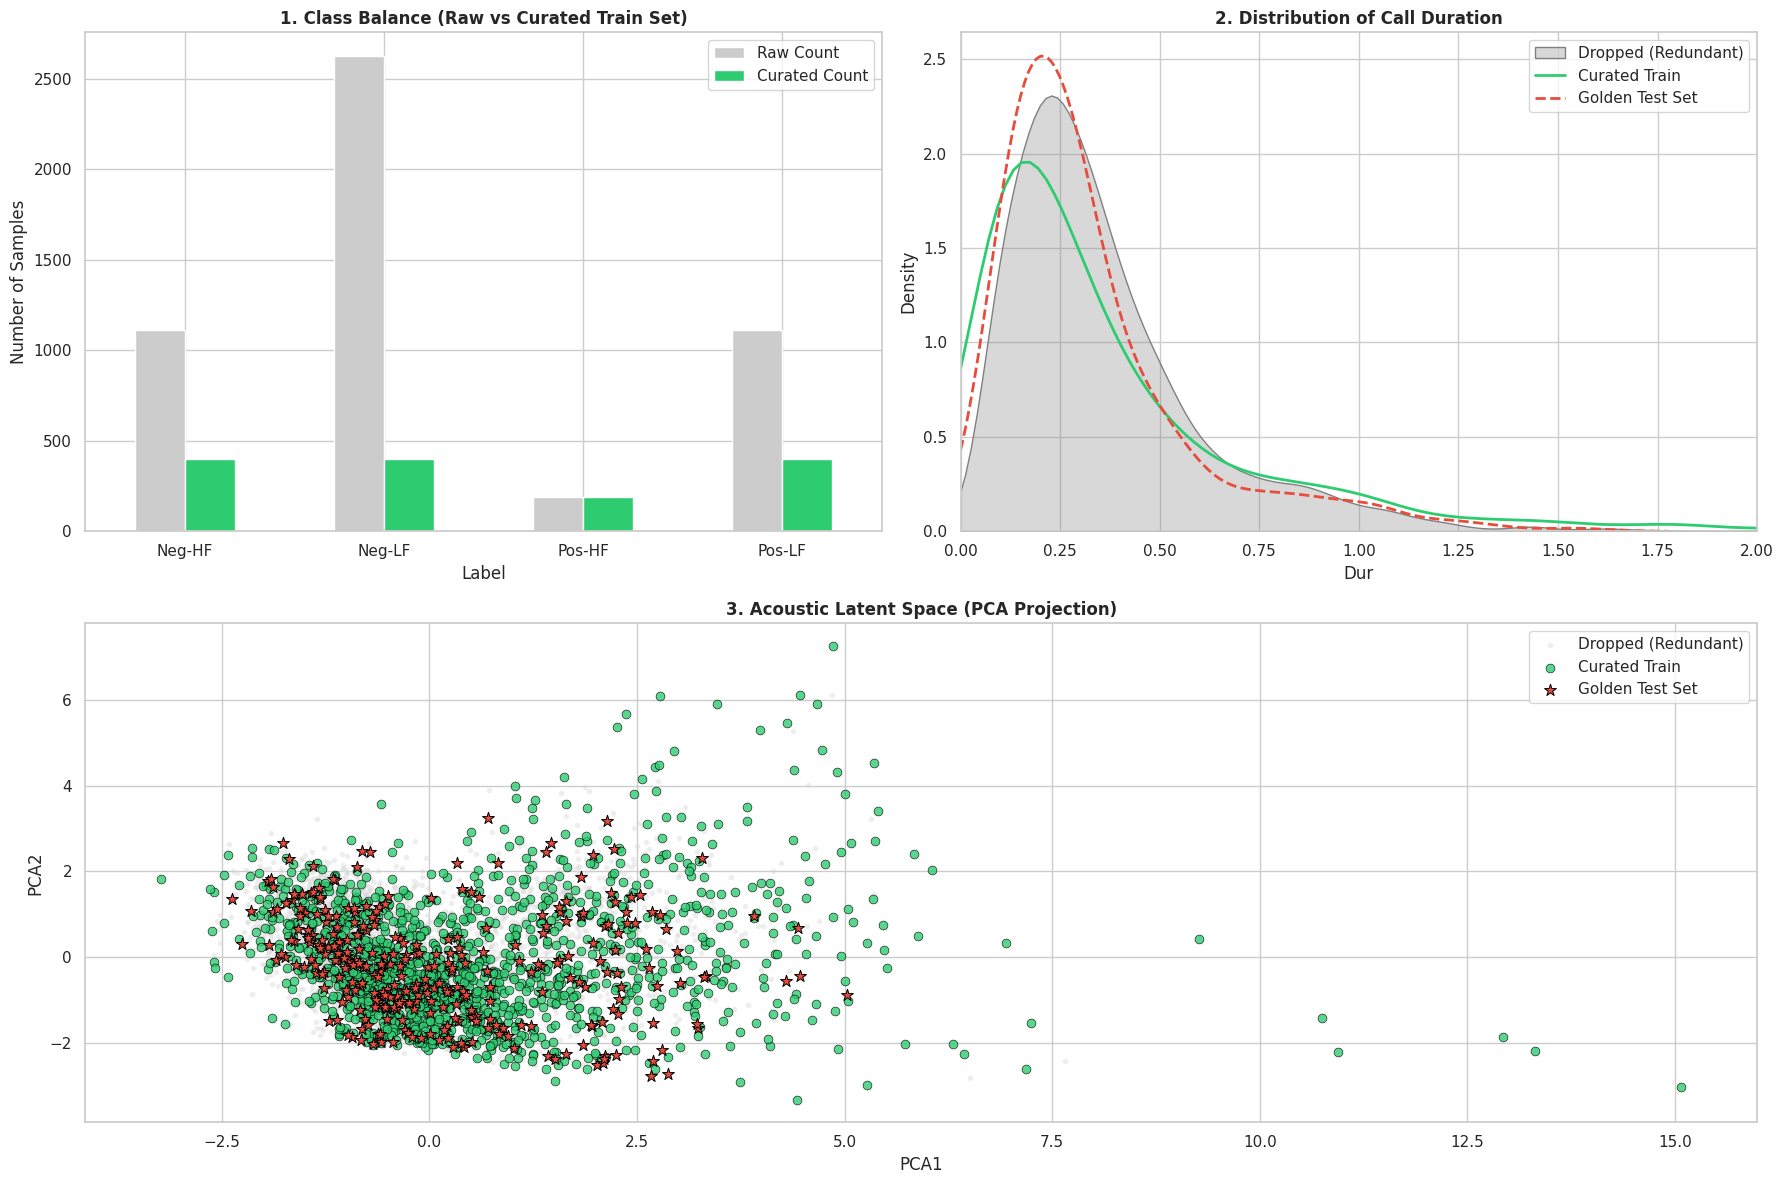

In [ ]:
#@title 3️⃣ Visualizing the Acoustic Curation & Latent Space
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

print("=" * 80)
print(" 👁️ VISUALIZING THE CURATION DECISIONS")
print("=" * 80)

# Mark the statuses for plotting
raw_train_df['Status'] = 'Dropped (Redundant)'
raw_train_df.loc[raw_train_df['Audio Filename'].isin(curated_train_df['Audio Filename']), 'Status'] = 'Curated Train'
test_df_final['Status'] = 'Golden Test Set'

viz_df = pd.concat([raw_train_df, test_df_final])

# Ensure NaNs are filled for PCA
for f in features:
    viz_df[f] = viz_df[f].fillna(viz_df[f].median())

sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(18, 12))

# 1. Class Balance
ax1 = plt.subplot(2, 2, 1)
raw_counts = raw_train_df.groupby(['Valence', 'Type']).size().reset_index(name='Raw Count')
raw_counts['Label'] = raw_counts['Valence'] + "-" + raw_counts['Type']
curated_counts = curated_train_df.groupby(['Valence', 'Type']).size().reset_index(name='Curated Count')
curated_counts['Label'] = curated_counts['Valence'] + "-" + curated_counts['Type']
balance_df = pd.merge(raw_counts, curated_counts, on=['Valence', 'Type', 'Label'], how='outer').fillna(0)
balance_df.plot(x='Label', y=['Raw Count', 'Curated Count'], kind='bar', ax=ax1, color=['#cccccc', '#2ecc71'])
ax1.set_title("1. Class Balance (Raw vs Curated Train Set)", fontweight='bold')
ax1.set_ylabel("Number of Samples")
ax1.tick_params(axis='x', rotation=0)

# 2. Distribution
ax2 = plt.subplot(2, 2, 2)
sns.kdeplot(data=viz_df[viz_df['Status'] == 'Dropped (Redundant)'], x='Dur', fill=True, color='grey', alpha=0.3, label='Dropped (Redundant)')
sns.kdeplot(data=viz_df[viz_df['Status'] == 'Curated Train'], x='Dur', fill=False, color='#2ecc71', linewidth=2, label='Curated Train')
sns.kdeplot(data=viz_df[viz_df['Status'] == 'Golden Test Set'], x='Dur', fill=False, color='#e74c3c', linewidth=2, linestyle='--', label='Golden Test Set')
ax2.set_title("2. Distribution of Call Duration", fontweight='bold')
ax2.set_xlim(0, 2.0)
ax2.legend()

# 3. PCA Latent Space
ax3 = plt.subplot(2, 1, 2)
X_all = scaler.transform(viz_df[features])
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(X_all)
viz_df['PCA1'] = pca_coords[:, 0]
viz_df['PCA2'] = pca_coords[:, 1]

sns.scatterplot(data=viz_df[viz_df['Status'] == 'Dropped (Redundant)'], x='PCA1', y='PCA2', color='lightgrey', alpha=0.4, s=15, ax=ax3, label='Dropped (Redundant)')
sns.scatterplot(data=viz_df[viz_df['Status'] == 'Curated Train'], x='PCA1', y='PCA2', color='#2ecc71', alpha=0.8, s=40, edgecolor='black', ax=ax3, label='Curated Train')
sns.scatterplot(data=viz_df[viz_df['Status'] == 'Golden Test Set'], x='PCA1', y='PCA2', color='#e74c3c', alpha=1.0, s=80, marker='*', edgecolor='black', ax=ax3, label='Golden Test Set')

ax3.set_title("3. Acoustic Latent Space (PCA Projection)", fontweight='bold')
ax3.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
#@title 4️⃣ Push SOTA Dataset to Hugging Face
from datasets import DatasetDict
from huggingface_hub import login
from google.colab import userdata

print("Mapping back to Audio/Image features... (this takes a moment)")
test_filenames = set(test_df_final['Audio Filename'])
train_filenames = set(curated_train_df['Audio Filename'])

# We filter the ORIGINAL HF dataset using the Filenames to preserve Audio/Image features
final_test_dataset = hf_dataset.filter(lambda r: r['Audio Filename'] in test_filenames)
final_train_dataset = hf_dataset.filter(lambda r: r['Audio Filename'] in train_filenames)

leak_free_dataset_dict = DatasetDict({
    'train': final_train_dataset,
    'test': final_test_dataset
})

print("\n" + "=" * 80)
print("🚀 PUSHING TO HUGGINGFACE HUB")
print("=" * 80)

hf_token = userdata.get("HF_TOKEN_2")
login(token=hf_token)

HF_REPO_ID = "oliveirabruno01/soundwel-pig-vocalizations"
leak_free_dataset_dict.push_to_hub(HF_REPO_ID, private=False)

print("✅ Data architecture complete! Leak-free splits pushed to Hub.")

Mapping back to Audio/Image features... (this takes a moment)


Filter:   0%|          | 0/6887 [00:00<?, ? examples/s]


🚀 PUSHING TO HUGGINGFACE HUB


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/1392 [00:00<?, ? examples/s]

...

Creating parquet from Arrow format:   0%|          | 0/4 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  24%|##4       | 4.15MB / 17.1MB            

✅ Data architecture complete! Leak-free splits pushed to Hub.


In [ ]:
# Re-push the original full dataset as the "raw" split
hf_dataset.push_to_hub("oliveirabruno01/soundwel-pig-vocalizations", split="raw", private=False)

Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/6887 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/69 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  32%|###2      |  120MB /  370MB            

README.md: 0.00B [00:00, ?B/s]

CommitInfo(commit_url='https://huggingface.co/datasets/oliveirabruno01/soundwel-pig-vocalizations/commit/4164e39798c2e65bce5ef8d56159d98e1267f577', commit_message='Upload dataset', commit_description='', oid='4164e39798c2e65bce5ef8d56159d98e1267f577', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/oliveirabruno01/soundwel-pig-vocalizations', endpoint='https://huggingface.co', repo_type='dataset', repo_id='oliveirabruno01/soundwel-pig-vocalizations'), pr_revision=None, pr_num=None)